# Export as a script and submit it as a Ray Job

The builder exports a graph as a standalone Python script (functions inlined, an if __name__ == "__main__" entry point) and writes a shell script that submits it with ray job submit.

**When to use it.** Moving a notebook prototype to a cluster, a scheduler or CI without the notebook.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

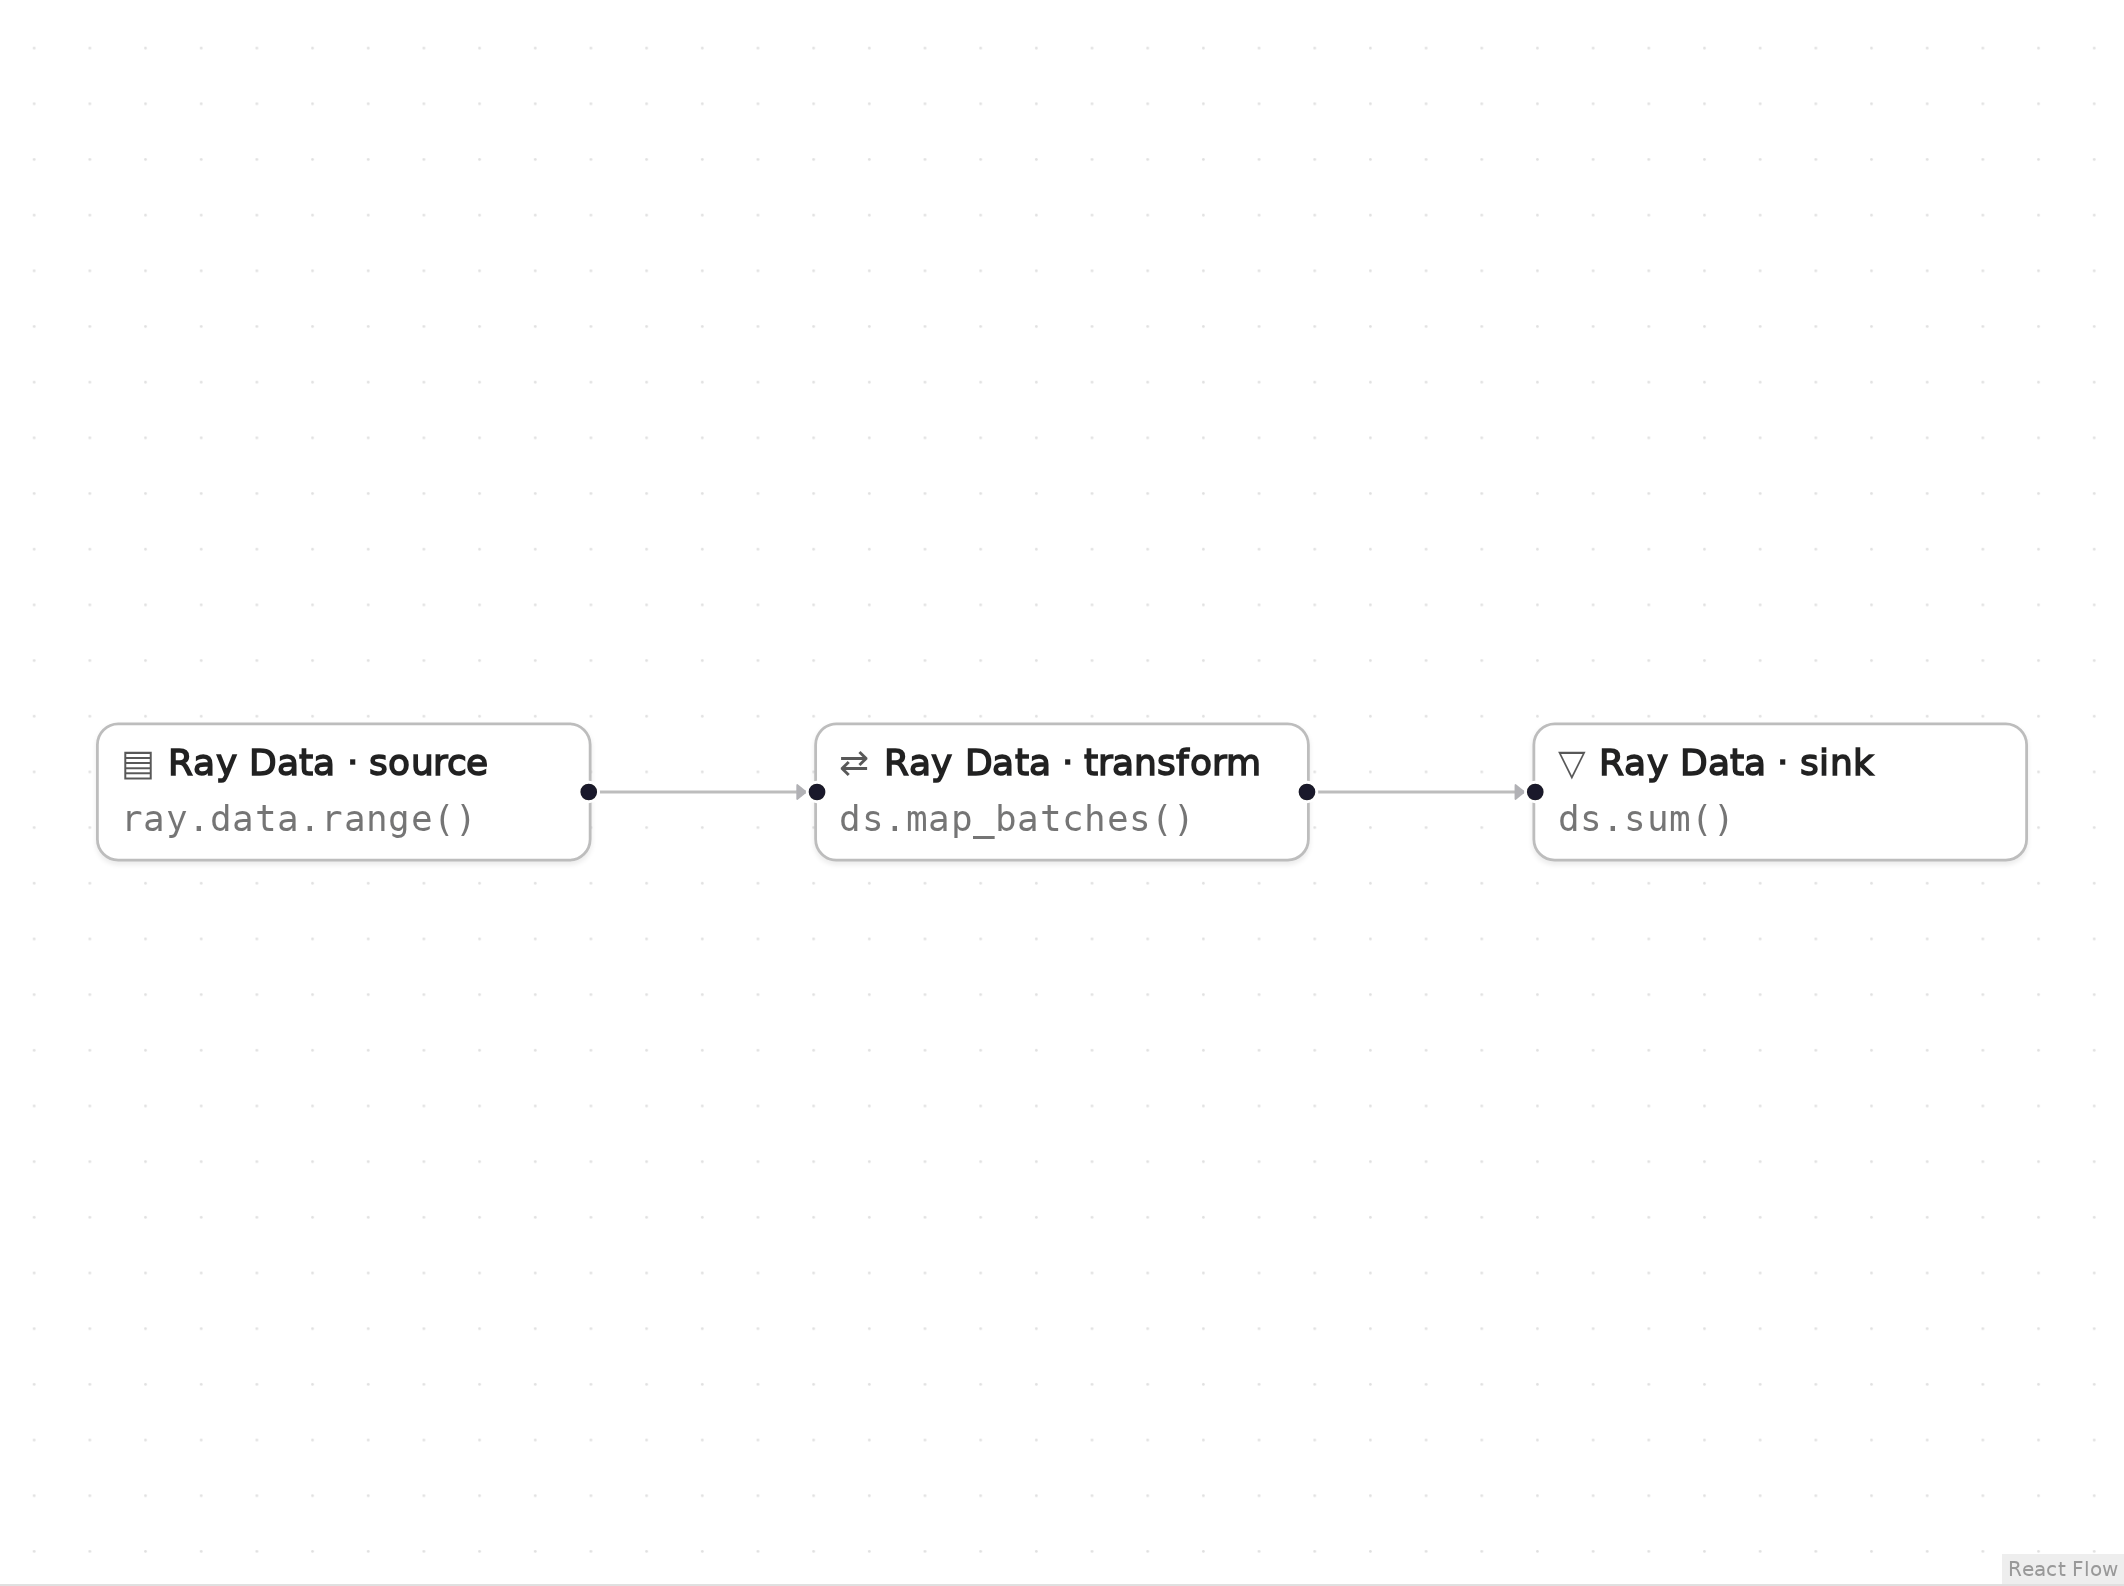

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
def square(batch):
    batch["id"] = batch["id"] ** 2
    return batch

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

import ray

if not ray.is_initialized():
    ray.init()

ds = ray.data.range(1000)
ds = ds.map_batches(square)
total = ds.sum("id")

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
assert total == sum(i * i for i in range(1000)), total
print("sum of squares =", total)

sum of squares = 332833500


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3 and 5–6)

```python
# Generated with Eugo's visual Ray builder
...
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Source** (node `n1`, line 8)

```python
ds = ray.data.range(1000)
```

A thousand rows.

**Transform** (node `n2`, line 9)

```python
ds = ds.map_batches(square)
```

map_batches(square) squares each id.

**Sink** (node `n3`, line 10)

```python
total = ds.sum("id")
```

sum("id") adds them up. In the exported script this runs inside the __main__ block between ray.init() and ray.shutdown().

## Other ways the builder can emit this graph

The builder can emit the same graph in other forms. They are shown here as text and are not run by this notebook.

### As a standalone script (`export_script_and_job.py`)

The builder can export the graph as a Python module: the user functions are copied in and the Ray calls go under `if __name__ == "__main__":`. It was run as a script on Ray 2.55.1.

```python
# Generated with Eugo's visual Ray builder

# Best-effort standalone export: cells defining referenced functions/classes
# were inlined. Transitive helpers from OTHER cells, referenced notebook VARIABLES
# (e.g. a Data source's `df`), and notebook magics (commented out) may need manual
# edits. Re-exporting overwrites this file.

import ray

def square(batch):
    batch["id"] = batch["id"] ** 2
    return batch

if __name__ == "__main__":
    ray.init()

    ds = ray.data.range(1000)
    ds = ds.map_batches(square)
    total = ds.sum("id")
    ray.shutdown()
```

### Submit the script as a Ray Job

The builder also writes a small shell script that submits the exported module with the Ray Jobs CLI. It needs a running Ray cluster whose dashboard (the Jobs API) is reachable at the address in the script, so it was not run here.

```bash
#!/usr/bin/env bash
set -euo pipefail

# Submit this Ray DAG to a cluster as a job — Ray Jobs CLI (`ray job submit`), verified on Ray 2.55.1.
# `--working-dir .` packages and ships THIS directory to the cluster (the file-upload mechanism),
# so run this script from the directory that contains export_script_and_job.py.
# Limits: --address defaults to the local dashboard (edit it for a remote cluster); no
# programmatic JobSubmissionClient script is generated. pip/conda/env-var runtime_env deps set in
# the graph DO ride the entrypoint ray.init and apply (only an in-script working_dir clashes).
# Re-exporting overwrites this file.

ray job submit --address 'http://127.0.0.1:8265' --working-dir . -- python -- 'export_script_and_job.py'
```

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()